# Avance 5. Modelo final: comparación de ensambles y evaluación en datos no vistos

**Inferencia de propiedades físicas de galaxias a partir de imágenes multibanda** · Instituto Tecnológico y de Estudios Superiores de Monterrey · Maestría en Inteligencia Artificial Aplicada · **Equipo 24** · Colaboración con el Instituto de Astronomía de la UNAM

| Integrante | Matrícula |
|---|---|
| Luz Copelia Minutti Pérez | A01796921 |
| Erick Alberto Bustos Cruz | A01378966 |
| José Florencio Maguey Peralta | A01796727 |

**Asesores:** Dr. Iván Reyes Amezcua (ITESM) · Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata (IA-UNAM)

**Fase de CRISP-ML(Q):** 3, *Machine Learning Model Engineering* (Studer et al. 2021). **Avance 5:** modelo final.

## 1. Planteamiento

En el Avance 4 comparamos seis modelos individuales y vimos que ninguno domina en todas las propiedades: la ResNet50 con redshift estima mejor la masa, y DINOv3 con LoRA estima mejor la SFR y el D4000. En este avance construimos ensambles para aprovechar esa complementariedad, de dos tipos. Los **homogéneos** combinan tres redes de la misma arquitectura entrenadas con semillas distintas; los **heterogéneos** combinan arquitecturas distintas. Este cuaderno reúne todos los modelos, los compara con los mismos criterios, elige el modelo final y lo evalúa en el conjunto de prueba.

El trabajo está repartido en cuatro cuadernos de esta carpeta:

| Cuaderno | Contenido |
|---|---|
| `Ensambles_Homogeneos_ResNet50_D_E_vf.ipynb` | Ensambles homogéneos de ResNet50 (variantes D y E, tres semillas cada una) y búsqueda de sus pesos, evaluados en validación |
| `Modelos_Base_DINOv3_ConvNeXt_EfficientNet.ipynb` | Entrenamiento en GPU de los miembros nuevos y exportación de las predicciones de nuestras redes |
| `Ensambles_Heterogeneos_Mezcla_MetaAprendiz.ipynb` | Ensambles heterogéneos: mezcla convexa y meta-aprendiz, con su optimización y su validación anidada |
| `Avance5.24.ipynb` | Comparación final de los modelos individuales y de los ensambles, selección del modelo final y evaluación en prueba |

El avance pide al menos cuatro ensambles, y comparamos siete. Cinco son homogéneos: los dos de ResNet50 de Luz Minutti (variantes D y E) y los de nuestras tres familias con redshift (DINOv3, ConvNeXt y EfficientNet-B3, tres semillas cada una). Dos son heterogéneos: la mezcla convexa y el meta-aprendiz. Los ensambles de Luz se reportan con las métricas de validación de su cuaderno: no contamos con sus predicciones galaxia por galaxia ni con predicciones de prueba, así que entran a la comparación como referencia, pero no a la regla de selección ni a la evaluación en prueba.

Ninguno de los otros cuadernos de este avance calculó métricas con el conjunto de prueba. Aquí elegimos el modelo final con las galaxias de validación, registramos la elección con una huella de sus predicciones y solo después abrimos la prueba, una sola vez.

**El interruptor de la pista.** La pista `con_redshift` usa modelos que reciben el redshift espectroscópico como entrada, igual que la variante E de ResNet50; la pista `solo_imagen` usa modelos que solo reciben la imagen, que es la situación de la mayoría de las galaxias a las que queremos extender las estimaciones. Con `PISTA = "con_redshift"` (valor por defecto) se compara la primera y al cambiar la variable se compara la segunda. El cuaderno de ensambles heterogéneos debe haberse ejecutado antes con la misma pista. En esta entrega ejecutamos la pista `con_redshift`; la de solo imagen queda lista para ejecutarse con las predicciones que ya exportamos.

## 2. Parámetros

| Parámetro | Valor | Significado |
|---|---|---|
| `PISTA` | `con_redshift` | Interruptor de la pista: `con_redshift` o `solo_imagen` |
| `SEMILLA_REPRESENTANTE` | 42 | Semilla de la red que representa a cada familia como modelo individual, fijada antes de ver resultados |
| `N_REMUESTREOS` | 2000 | Remuestreos *bootstrap* para los intervalos de confianza |

| Pista | Familias que se combinan en los heterogéneos |
|---|---|
| `con_redshift` | `dinov3_z`, `convnext_z`, `efficientnet_z` |
| `solo_imagen` | `dinov3_imagen`, `convnext_imagen` y, si se entrenó, `efficientnet_imagen` |

In [1]:
import os
variable_entorno = os.environ.get          # las variables MA_* solo se usan en la prueba local reducida

# ------------------------------------------------------------------------------------------------
# INTERRUPTOR DE LA PISTA: "con_redshift" (redshift espectroscópico como entrada) o "solo_imagen".
PISTA = "con_redshift"
# ------------------------------------------------------------------------------------------------
PISTA = variable_entorno("MA_PISTA", PISTA)
PISTAS = {"con_redshift": {"heterogeneo": ["dinov3_z", "convnext_z", "efficientnet_z"], "otros": [],
                           "redshift_en_meta": True, "descripcion": "con el redshift espectroscópico como entrada"},
          "solo_imagen": {"heterogeneo": ["dinov3_imagen", "convnext_imagen", "efficientnet_imagen"], "otros": [],
                          "redshift_en_meta": False, "descripcion": "solo con la imagen"}}
if PISTA not in PISTAS:
    raise ValueError(f"PISTA debe ser una de {list(PISTAS)}")
OBJETIVOS = ("log_mstar", "log_sfr", "d4000")
NOMBRES = {"log_mstar": "log M* [dex]", "log_sfr": "log SFR [dex]", "d4000": "D4000"}
CORTO = {"log_mstar": "M*", "log_sfr": "SFR", "d4000": "D4000"}
NOMBRE_H1, NOMBRE_H2 = "Heterogéneo 1: mezcla convexa", "Heterogéneo 2: meta-aprendiz"
ARCHIVO_H1, ARCHIVO_H2 = "h1_mezcla_convexa", "h2_meta_aprendiz"

SEMILLA_REPRESENTANTE = 42
N_REMUESTREOS = int(variable_entorno("MA_REMUESTREOS", "2000"))
print(f"Pista: {PISTA} ({PISTAS[PISTA]['descripcion']})")

Pista: con_redshift (con el redshift espectroscópico como entrada)


## 3. Entorno

Este cuaderno no necesita GPU ni acceso a las imágenes: trabaja con las predicciones que cada red exportó en un formato común (un archivo pequeño por familia y semilla, con las galaxias de validación y de prueba), que están en el repositorio. Descargamos el código del equipo para ligar los resultados a una versión concreta.

In [2]:
import sys, json, time, subprocess, platform, warnings, hashlib
from pathlib import Path
from datetime import datetime, timezone

EN_COLAB = "google.colab" in sys.modules
URL_REPOSITORIO = "https://github.com/erteck/InferenciaPropiedadesFisicas.git"
CARPETA_REPOSITORIO = Path(variable_entorno("MA_CARPETA_REPOSITORIO", "/content/InferenciaPropiedadesFisicas"))
if EN_COLAB:
    if not CARPETA_REPOSITORIO.exists():
        subprocess.run(["git", "clone", "-q", URL_REPOSITORIO, str(CARPETA_REPOSITORIO)], check=True)
    subprocess.run(["git", "-C", str(CARPETA_REPOSITORIO), "pull", "-q"], check=True)
elif not (CARPETA_REPOSITORIO / "src").exists():
    CARPETA_REPOSITORIO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "modelos_alternativos").exists())
sys.path.insert(0, str(CARPETA_REPOSITORIO))
COMMIT = subprocess.run(["git", "-C", str(CARPETA_REPOSITORIO), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display
from src.modelos_alternativos import ensambles, evaluacion, predicciones

CARPETA_PREDICCIONES = Path(variable_entorno("MA_CARPETA_PREDICCIONES", str(CARPETA_REPOSITORIO / "Avance 5. Modelo final" / "predicciones")))
CARPETA_ENTREGA = CARPETA_PREDICCIONES.parent
CARPETA_HETEROGENEOS = CARPETA_ENTREGA / "ensambles_heterogeneos"
pd.set_option("display.precision", 4, "display.max_columns", 40, "display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version(), "· commit", COMMIT[:12], "·", CARPETA_PREDICCIONES)

Python 3.10.13 · commit 42078497a863 · /Users/erteck/Documents/GitHub/InferenciaPropiedadesFisicas/Avance 5. Modelo final/predicciones


## 4. Predicciones de los modelos

Leemos las predicciones de todas las redes y las alineamos por el identificador de cada galaxia (`mangaid`), nunca por posición, con la misma regla que el cuaderno de ensambles heterogéneos: si alguna red no trae predicción para una galaxia, esa galaxia se descarta para todas. También se comprueba que las etiquetas y el redshift coincidan entre archivos. La métrica principal, el promedio entre propiedades del MSE normalizado por la desviación de entrenamiento (cuanto menor, mejor), usa una escala que viene en un archivo aparte porque este cuaderno no tiene acceso al catálogo.

In [3]:
TABLA = predicciones.leer_carpeta(CARPETA_PREDICCIONES)
ESCALA = predicciones.leer_escala(CARPETA_PREDICCIONES)
CONFIGURACION = PISTAS[PISTA]
CANDIDATAS = CONFIGURACION["heterogeneo"] + CONFIGURACION["otros"]
DISPONIBLES = [f for f in CANDIDATAS if f in set(TABLA[TABLA.particion == "Validation"].familia) and f in set(TABLA[TABLA.particion == "Test"].familia)]
FALTAN = [f for f in CANDIDATAS if f not in DISPONIBLES]
if FALTAN:
    print("Aviso: no hay predicciones de validación y de prueba para:", FALTAN, "· se trabaja sin ellas")
FAMILIAS_HETEROGENEO = [f for f in CONFIGURACION["heterogeneo"] if f in DISPONIBLES]
if len(FAMILIAS_HETEROGENEO) < 2:
    raise ValueError("Un ensamble heterogéneo necesita al menos dos arquitecturas con predicciones")

# Las galaxias son las que tienen predicción en todas las familias disponibles, igual en los dos cuadernos sin GPU.
VAL = predicciones.construir_conjunto(TABLA, "Validation", DISPONIBLES)
PRUEBA = predicciones.construir_conjunto(TABLA, "Test", DISPONIBLES)
Y_VAL, Y_PRUEBA, Z_VAL, Z_PRUEBA = VAL.y, PRUEBA.y, VAL.redshift, PRUEBA.redshift
P_VAL = VAL.medias(FAMILIAS_HETEROGENEO)              # (familias, galaxias, propiedades): promedio de las semillas
P_PRUEBA = PRUEBA.medias(FAMILIAS_HETEROGENEO)
HUELLA_MIEMBROS = predicciones.huella_miembros(VAL, FAMILIAS_HETEROGENEO)
resumen_carga = pd.DataFrame({"semillas": {f: len(VAL.semillas[f]) for f in DISPONIBLES},
                              "galaxias de validación": len(VAL.ids), "galaxias de prueba": len(PRUEBA.ids),
                              "tta": TABLA.groupby("familia").tta.first().reindex(DISPONIBLES).map({True: "sí", False: "no"}),
                              "en los heterogéneos": {f: "sí" if f in FAMILIAS_HETEROGENEO else "no" for f in DISPONIBLES}})
display(resumen_carga)
print("Desviación de cada propiedad en entrenamiento:", dict(zip(OBJETIVOS, ESCALA.round(4))))

,semillas,galaxias de validación,galaxias de prueba,tta,en los heterogéneos
dinov3_z,3,1261,917,sí,sí
convnext_z,3,1261,917,sí,sí
efficientnet_z,3,1261,917,sí,sí


Desviación de cada propiedad en entrenamiento: {'log_mstar': np.float64(0.6467), 'log_sfr': np.float64(1.1613), 'd4000': np.float64(0.2427)}


Después leemos los dos ensambles heterogéneos. Antes de usarlos comprobamos que se ajustaron con la misma pista, las mismas familias y exactamente las mismas predicciones de los miembros que acabamos de leer, comparando la huella que guardó su cuaderno con la que calculamos aquí. Si alguna red se volvió a exportar después de ajustar los ensambles, la huella no coincide y el cuaderno se detiene.

In [4]:
RUTA_CONFIGURACION = CARPETA_HETEROGENEOS / f"heterogeneos_{PISTA}.json"
if not RUTA_CONFIGURACION.exists():
    raise FileNotFoundError(f"No existe {RUTA_CONFIGURACION}: ejecuta antes Ensambles_Heterogeneos_Mezcla_MetaAprendiz.ipynb con PISTA = '{PISTA}'")
HETEROGENEOS = json.loads(RUTA_CONFIGURACION.read_text())
if HETEROGENEOS["pista"] != PISTA or HETEROGENEOS["familias"] != FAMILIAS_HETEROGENEO:
    raise ValueError(f"Los ensambles heterogéneos se ajustaron con la pista {HETEROGENEOS['pista']} y las familias {HETEROGENEOS['familias']}")
if HETEROGENEOS["huella_miembros"] != HUELLA_MIEMBROS:
    raise ValueError("Las predicciones de los miembros cambiaron desde que se ajustaron los ensambles heterogéneos: vuelve a ejecutar ese cuaderno")
OOF, PRED_PRUEBA_HETEROGENEO = {}, {}
for archivo, nombre in ((ARCHIVO_H1, NOMBRE_H1), (ARCHIVO_H2, NOMBRE_H2)):
    OOF[nombre], PRED_PRUEBA_HETEROGENEO[nombre] = predicciones.leer_ensamble(CARPETA_HETEROGENEOS, PISTA, archivo, VAL.ids, PRUEBA.ids)
PESOS_H1 = np.asarray(HETEROGENEOS[ARCHIVO_H1]["pesos"], float)
APORTE = pd.read_csv(CARPETA_HETEROGENEOS / f"aporte_familias_{PISTA}.csv")
display(pd.DataFrame({nombre: {"configuración": {k: v for k, v in HETEROGENEOS[a]["configuracion"].items()},
                               "criterio de la validación anidada": f"{HETEROGENEOS[a]['criterio_medio']:.4f} ± {HETEROGENEOS[a]['criterio_desviacion']:.4f}",
                               "repeticiones": len(OOF[nombre]), "ajustado el": HETEROGENEOS["fecha_utc"][:19], "commit": HETEROGENEOS["commit"][:12]}
                      for a, nombre in ((ARCHIVO_H1, NOMBRE_H1), (ARCHIVO_H2, NOMBRE_H2))}).T)
print("Huella de los miembros verificada:", HUELLA_MIEMBROS[:16])

,configuración,criterio de la validación anidada,repeticiones,ajustado el,commit
Heterogéneo 1: mezcla convexa,"{'tipo': 'mezcla_convexa', 'lambda': 0.01, 'al...",0.1037 ± 0.0002,3,2026-11-01T00:40:09,6567def00d82
Heterogéneo 2: meta-aprendiz,"{'tipo': 'bosque_residual', 'profundidad': 2, ...",0.1046 ± 0.0003,3,2026-11-01T00:40:09,6567def00d82


Huella de los miembros verificada: f232e1eafa88717b


Para el costo de cada modelo juntamos los tiempos que registró el cuaderno de entrenamiento de los modelos base, todos medidos en la misma GPU A100: los minutos de entrenamiento de cada red y los milisegundos por galaxia al predecir sin TTA. Ese cuaderno midió también el tiempo de uso de la ResNet50 con la misma arquitectura y el mismo tamaño de imagen (la duración de una predicción no depende de los valores de los pesos), para poder comparar el costo de usar los ensambles de Luz. Los tiempos de entrenamiento de la ResNet50 son los que reportó Luz, medidos en una GPU NVIDIA RTX A4000, más lenta que la A100, así que anotamos siempre el equipo.

In [5]:
archivos_tiempos = sorted(CARPETA_PREDICCIONES.glob("tiempos_modelos*.csv"))
TIEMPOS = pd.concat([pd.read_csv(a) for a in archivos_tiempos], ignore_index=True) if archivos_tiempos else pd.DataFrame(
    columns=["familia", "semilla", "hardware", "minutos_entrenamiento", "ms_por_galaxia"])
primero_valido = lambda x: x.dropna().iloc[0] if x.notna().any() else np.nan
entrenamiento = TIEMPOS[TIEMPOS.minutos_entrenamiento.notna()]                # filas de entrenamiento (las de solo inferencia no cuentan)
COSTO_FAMILIA = pd.DataFrame({"minutos_por_red": entrenamiento.groupby("familia").minutos_entrenamiento.mean(),
                              "hardware": entrenamiento.groupby("familia").hardware.first(),
                              "ms_por_galaxia": TIEMPOS.groupby("familia").ms_por_galaxia.agg(primero_valido)})
MS_RESNET50 = COSTO_FAMILIA.ms_por_galaxia.get("resnet50_e" if PISTA == "con_redshift" else "resnet50_g", np.nan)

def costo_de(familias, redes_por_familia=None):
    # Costo de un modelo que ejecuta `redes_por_familia` redes de cada familia (por defecto, todas sus semillas).
    n = {f: (redes_por_familia or len(VAL.semillas[f])) for f in familias}
    minutos = sum(n[f] * COSTO_FAMILIA.minutos_por_red.get(f, np.nan) for f in familias)
    ms = sum(n[f] * COSTO_FAMILIA.ms_por_galaxia.get(f, np.nan) for f in familias)
    equipos = sorted({h if isinstance(h, str) else "no reportado" for h in (COSTO_FAMILIA.hardware.get(f, np.nan) for f in familias)})
    return {"redes por galaxia": sum(n.values()), "minutos de entrenamiento": minutos, "ms por galaxia": ms,
            "horas de GPU por millón": ensambles.horas_gpu_por_millon(ms) if np.isfinite(ms) else np.nan, "equipo": " + ".join(equipos)}
display(COSTO_FAMILIA.reindex(DISPONIBLES).round(3).fillna("no reportado"))

,minutos_por_red,hardware,ms_por_galaxia
familia,,,
dinov3_z,24.040,NVIDIA A100-SXM4-40GB,2.692
convnext_z,6.112,NVIDIA A100-SXM4-40GB,0.451
efficientnet_z,6.392,NVIDIA A100-SXM4-40GB,0.396


## 5. Modelos individuales y ensambles homogéneos

Cada familia se representa de dos formas. Como **modelo individual** usamos la red de la semilla 42, la misma que representó a la variante E de ResNet50 en el Avance 4, y la fijamos antes de ver los resultados para no elegir la semilla que mejor salió. Como **ensamble homogéneo** usamos el promedio uniforme de sus tres semillas. Luz Minutti buscó además pesos aprendidos para sus ensambles de ResNet50. En la variante E la búsqueda eligió el propio promedio uniforme, y en la D eligió pesos por propiedad con λ = 0.01, cuya ventaja dentro de la búsqueda fue de una diezmilésima (0.11899 contra 0.11910). Por eso usamos el promedio uniforme en nuestras familias: no tiene hiperparámetros y no pierde nada que se distinga del ruido.

La tabla ordena nuestras redes y sus ensambles homogéneos por la métrica principal en validación. En estos modelos no se ajusta nada con esas galaxias, así que sus valores son directamente comparables. Nuestras predicciones promedian las 8 simetrías de cada imagen (TTA), que en el Avance 4 redujo el criterio entre 1.4 y 4 %; las cifras de Luz son sin TTA, y lo tenemos en cuenta al compararlas.

In [6]:
def metricas_largas(nombre, y, prediccion, **extra):
    tabla = evaluacion.tabla_metricas(y, prediccion, OBJETIVOS, ESCALA).set_index("objetivo")
    return {"modelo": nombre, **extra, "criterio": tabla.MSE_normalizado.mean(),
            **{f"RMSE {CORTO[t]}": tabla.loc[t, "RMSE"] for t in OBJETIVOS}, **{f"MAE {CORTO[t]}": tabla.loc[t, "MAE"] for t in OBJETIVOS},
            **{f"R2 {CORTO[t]}": tabla.loc[t, "R2"] for t in OBJETIVOS}}

def indice_representante(familia):
    semillas = VAL.semillas[familia]
    return semillas.index(SEMILLA_REPRESENTANTE) if SEMILLA_REPRESENTANTE in semillas else 0

INDIVIDUAL_VAL = {f: VAL.pred[f][indice_representante(f)] for f in DISPONIBLES}
INDIVIDUAL_PRUEBA = {f: PRUEBA.pred[f][indice_representante(f)] for f in DISPONIBLES}
HOMOGENEO_VAL = {f: VAL.media(f) for f in DISPONIBLES}
HOMOGENEO_PRUEBA = {f: PRUEBA.media(f) for f in DISPONIBLES}

filas = []
for f in DISPONIBLES:
    por_semilla = [ensambles.criterio(Y_VAL, VAL.pred[f][i], ESCALA) for i in range(len(VAL.semillas[f]))]
    filas.append({**metricas_largas(f"{f} · individual (semilla {VAL.semillas[f][indice_representante(f)]})", Y_VAL, INDIVIDUAL_VAL[f], tipo="individual", familia=f),
                  "criterio medio de las semillas": np.mean(por_semilla), "desviación entre semillas": np.std(por_semilla, ddof=1) if len(por_semilla) > 1 else np.nan})
    filas.append(metricas_largas(f"{f} · ensamble homogéneo ({len(VAL.semillas[f])} semillas)", Y_VAL, HOMOGENEO_VAL[f], tipo="homogéneo", familia=f))
BASE = pd.DataFrame(filas).sort_values("criterio").reset_index(drop=True)
display(BASE[["modelo", "criterio", "criterio medio de las semillas", "desviación entre semillas", "RMSE M*", "RMSE SFR", "RMSE D4000", "R2 M*", "R2 SFR", "R2 D4000"]]
        .round(4).fillna("no aplica"))
MEJOR_INDIVIDUAL = BASE[BASE.tipo == "individual"].iloc[0].familia
print("Mejor modelo individual (semilla representante):", MEJOR_INDIVIDUAL)

,modelo,criterio,criterio medio de las semillas,desviación entre semillas,RMSE M*,RMSE SFR,RMSE D4000,R2 M*,R2 SFR,R2 D4000
0,dinov3_z · ensamble homogéneo (3 semillas),0.1081,no aplica,no aplica,0.1079,0.5428,0.0678,0.9729,0.7823,0.9173
1,dinov3_z · individual (semilla 42),0.1092,0.1097,0.0004,0.1112,0.5432,0.0684,0.9713,0.7821,0.9158
2,convnext_z · ensamble homogéneo (3 semillas),0.1102,no aplica,no aplica,0.1025,0.5508,0.0688,0.9756,0.7759,0.9147
3,efficientnet_z · ensamble homogéneo (3 semillas),0.1165,no aplica,no aplica,0.1038,0.5711,0.0694,0.9749,0.7591,0.9132
4,convnext_z · individual (semilla 42),0.1170,0.1157,0.0021,0.1086,0.5607,0.0727,0.9726,0.7677,0.9049
5,efficientnet_z · individual (semilla 42),0.1215,0.1227,0.0011,0.1059,0.5847,0.0704,0.9739,0.7474,0.9107


Mejor modelo individual (semilla representante): dinov3_z


Con las predicciones con TTA, DINOv3 con redshift es el mejor modelo individual (0.1092 con la semilla 42), y su ensamble homogéneo lo mejora a 0.1081. Promediar semillas ayuda más cuando las semillas difieren más: en ConvNeXt, cuya desviación entre semillas es de 0.0021, el homogéneo baja el criterio de 0.1170 a 0.1102 (6 %), y en DINOv3, con una desviación de 0.0004, solo 1 %. Los tres ensambles homogéneos de nuestras familias superan en validación al mejor ensamble homogéneo de Luz (ResNet50 E, 0.1186), aunque una parte de esa diferencia viene del TTA, que nuestras predicciones usan y las suyas no.

## 6. Comparación en validación

Reunimos el mejor modelo individual, los ensambles homogéneos y los dos heterogéneos, ordenados por la métrica principal, con el RMSE, el MAE y el R² de cada propiedad y con el costo de cada uno. Para los heterogéneos usamos sus predicciones fuera de pliegue de la validación anidada, de modo que ninguna galaxia fue predicha por un combinador ajustado con su propia etiqueta; su criterio es el promedio de las repeticiones y su desviación indica cuánto cambia con la partición. Las métricas por propiedad de los heterogéneos son las de la primera repetición.

El costo tiene tres partes. Los minutos de entrenamiento suman el de todas las redes del modelo, sin contar las búsquedas de hiperparámetros ni el ajuste del combinador, que dura segundos. Las redes por galaxia y los milisegundos por galaxia (sin TTA, en la A100) miden lo que cuesta usarlo, y de ahí extrapolamos las horas de GPU para un millón de galaxias. Un ensamble necesita ejecutar todas sus redes, así que su costo de uso es la suma de los de sus miembros; las predicciones que combinamos usan TTA de 8 simetrías, que multiplicaría ese costo por ocho si se conserva al desplegar.

La tabla incluye, en amarillo en la gráfica, los ensambles homogéneos de Luz con las métricas de validación que reporta su cuaderno. Sirven como referencia, pero no entran a la regla de selección ni a la evaluación en prueba, porque para ambas se necesitan las predicciones de cada galaxia.

In [7]:
NOMBRE_INDIVIDUAL = f"Individual: {MEJOR_INDIVIDUAL} (mejor red individual)"
nombre_homogeneo = lambda f: f"Homogéneo: {f} ({len(VAL.semillas[f])} semillas)"
FAMILIAS_ACTIVAS_H1 = [f for i, f in enumerate(FAMILIAS_HETEROGENEO) if PESOS_H1[i].max() > 0.01]

PRED_VAL, PRED_PRUEBA, FAMILIA_DE = {NOMBRE_INDIVIDUAL: INDIVIDUAL_VAL[MEJOR_INDIVIDUAL]}, {NOMBRE_INDIVIDUAL: INDIVIDUAL_PRUEBA[MEJOR_INDIVIDUAL]}, {}
PERDIDAS = {NOMBRE_INDIVIDUAL: ensambles.perdida_por_galaxia(Y_VAL, INDIVIDUAL_VAL[MEJOR_INDIVIDUAL], ESCALA)}
FILAS = [{**metricas_largas(NOMBRE_INDIVIDUAL, Y_VAL, INDIVIDUAL_VAL[MEJOR_INDIVIDUAL], tipo="individual"), "desviación entre repeticiones": np.nan,
          **costo_de([MEJOR_INDIVIDUAL], redes_por_familia=1), "detalle": "una red"}]
for f in DISPONIBLES:
    n = nombre_homogeneo(f)
    PRED_VAL[n], PRED_PRUEBA[n] = HOMOGENEO_VAL[f], HOMOGENEO_PRUEBA[f]
    PERDIDAS[n] = ensambles.perdida_por_galaxia(Y_VAL, HOMOGENEO_VAL[f], ESCALA)
    FILAS.append({**metricas_largas(n, Y_VAL, HOMOGENEO_VAL[f], tipo="homogéneo"), "desviación entre repeticiones": np.nan, **costo_de([f]),
                  "detalle": "promedio uniforme de las semillas"})
for archivo, nombre, familias in ((ARCHIVO_H1, NOMBRE_H1, FAMILIAS_ACTIVAS_H1), (ARCHIVO_H2, NOMBRE_H2, FAMILIAS_HETEROGENEO)):
    PRED_VAL[nombre], PRED_PRUEBA[nombre] = OOF[nombre][0], PRED_PRUEBA_HETEROGENEO[nombre]
    PERDIDAS[nombre] = np.mean([ensambles.perdida_por_galaxia(Y_VAL, o, ESCALA) for o in OOF[nombre]], axis=0)   # promedio de las repeticiones
    config = HETEROGENEOS[archivo]["configuracion"]
    detalle = (f"λ={config['lambda']}, pesos {config['alcance'].replace('_', ' ')}" if archivo == ARCHIVO_H1 else f"tipo {config['tipo']}")
    FILAS.append({**metricas_largas(nombre, Y_VAL, OOF[nombre][0], tipo="heterogéneo"), "criterio": float(PERDIDAS[nombre].mean()),
                  "desviación entre repeticiones": HETEROGENEOS[archivo]["criterio_desviacion"], **costo_de(familias),
                  "detalle": f"{detalle}; ajuste del combinador {HETEROGENEOS[archivo]['segundos_ajuste_final']:.1f} s"})
COMPARACION = pd.DataFrame(FILAS).sort_values("criterio").reset_index(drop=True)
COMPARACION.index += 1; COMPARACION.index.name = "lugar"

# Ensambles de Luz: métricas de validación reportadas en su cuaderno (sin TTA); no hay predicciones por galaxia ni de prueba.
REPORTADOS = pd.DataFrame([
    {"modelo": "Homogéneo de Luz: ResNet50 E (3 semillas, reportado)", "criterio": 0.118602, "RMSE M*": 0.103993, "RMSE SFR": 0.573167, "RMSE D4000": 0.071312,
     "MAE M*": 0.078610, "MAE SFR": 0.380843, "MAE D4000": 0.051014, "R2 M*": 0.974848, "R2 SFR": 0.757310, "R2 D4000": 0.908433,
     "minutos de entrenamiento": 107.05, "detalle": "promedio uniforme de las semillas"},
    {"modelo": "Homogéneo de Luz: ResNet50 D (3 semillas, reportado)", "criterio": 0.119425, "RMSE M*": 0.104255, "RMSE SFR": 0.572519, "RMSE D4000": 0.072495,
     "MAE M*": 0.078730, "MAE SFR": 0.382535, "MAE D4000": 0.051780, "R2 M*": 0.974721, "R2 SFR": 0.757859, "R2 D4000": 0.905369,
     "minutos de entrenamiento": 109.85, "detalle": "pesos por propiedad, λ = 0.01"},
    {"modelo": "Individual de Luz: ResNet50 E semilla 42 (reportado)", "criterio": 0.127879, "RMSE M*": 0.108829, "RMSE SFR": 0.597520, "RMSE D4000": 0.073037,
     "MAE M*": 0.082898, "MAE SFR": 0.394586, "MAE D4000": 0.052342, "R2 M*": 0.972454, "R2 SFR": 0.736249, "R2 D4000": 0.903949,
     "minutos de entrenamiento": 39.63, "detalle": "una red"}]) if PISTA == "con_redshift" else pd.DataFrame()
if len(REPORTADOS):
    REPORTADOS["tipo"] = "reportado (Luz)"
    REPORTADOS["redes por galaxia"] = [3, 3, 1]
    REPORTADOS["ms por galaxia"] = REPORTADOS["redes por galaxia"] * MS_RESNET50
    REPORTADOS["horas de GPU por millón"] = REPORTADOS["ms por galaxia"].map(lambda ms: ensambles.horas_gpu_por_millon(ms) if np.isfinite(ms) else np.nan)
    REPORTADOS["equipo"] = "NVIDIA RTX A4000"
    REPORTADOS["desviación entre repeticiones"] = np.nan
TABLA_VALIDACION = pd.concat([COMPARACION, REPORTADOS], ignore_index=True).sort_values("criterio").reset_index(drop=True)
TABLA_VALIDACION.index += 1; TABLA_VALIDACION.index.name = "lugar"
display(TABLA_VALIDACION[["modelo", "tipo", "criterio", "desviación entre repeticiones", "RMSE M*", "RMSE SFR", "RMSE D4000", "MAE M*", "MAE SFR", "MAE D4000",
                          "R2 M*", "R2 SFR", "R2 D4000"]].round(4).fillna({"desviación entre repeticiones": "no aplica"}))
display(TABLA_VALIDACION[["modelo", "redes por galaxia", "minutos de entrenamiento", "equipo", "ms por galaxia", "horas de GPU por millón", "detalle"]]
        .round(3).fillna("no reportado"))

,modelo,tipo,criterio,desviación entre repeticiones,RMSE M*,RMSE SFR,RMSE D4000,MAE M*,MAE SFR,MAE D4000,R2 M*,R2 SFR,R2 D4000
lugar,,,,,,,,,,,,,
1,Heterogéneo 1: mezcla convexa,heterogéneo,0.1037,0.0002,0.0996,0.5354,0.0661,0.0762,0.3530,0.0460,0.9769,0.7883,0.9214
2,Heterogéneo 2: meta-aprendiz,heterogéneo,0.1046,0.0003,0.0999,0.5400,0.0662,0.0761,0.3559,0.0462,0.9768,0.7846,0.9211
3,Homogéneo: dinov3_z (3 semillas),homogéneo,0.1081,no aplica,0.1079,0.5428,0.0678,0.0827,0.3652,0.0471,0.9729,0.7823,0.9173
4,Individual: dinov3_z (mejor red individual),individual,0.1092,no aplica,0.1112,0.5432,0.0684,0.0858,0.3680,0.0476,0.9713,0.7821,0.9158
5,Homogéneo: convnext_z (3 semillas),homogéneo,0.1102,no aplica,0.1025,0.5508,0.0688,0.0788,0.3606,0.0480,0.9756,0.7759,0.9147
6,Homogéneo: efficientnet_z (3 semillas),homogéneo,0.1165,no aplica,0.1038,0.5711,0.0694,0.0791,0.3789,0.0497,0.9749,0.7591,0.9132
7,"Homogéneo de Luz: ResNet50 E (3 semillas, repo...",reportado (Luz),0.1186,no aplica,0.1040,0.5732,0.0713,0.0786,0.3808,0.0510,0.9748,0.7573,0.9084
8,"Homogéneo de Luz: ResNet50 D (3 semillas, repo...",reportado (Luz),0.1194,no aplica,0.1043,0.5725,0.0725,0.0787,0.3825,0.0518,0.9747,0.7579,0.9054
9,Individual de Luz: ResNet50 E semilla 42 (repo...,reportado (Luz),0.1279,no aplica,0.1088,0.5975,0.0730,0.0829,0.3946,0.0523,0.9725,0.7362,0.9039


,modelo,redes por galaxia,minutos de entrenamiento,equipo,ms por galaxia,horas de GPU por millón,detalle
lugar,,,,,,,
1,Heterogéneo 1: mezcla convexa,9,109.633,NVIDIA A100-SXM4-40GB,10.619,2.950,"λ=0.01, pesos por objetivo; ajuste del combina..."
2,Heterogéneo 2: meta-aprendiz,9,109.633,NVIDIA A100-SXM4-40GB,10.619,2.950,tipo bosque_residual; ajuste del combinador 28...
3,Homogéneo: dinov3_z (3 semillas),3,72.121,NVIDIA A100-SXM4-40GB,8.077,2.244,promedio uniforme de las semillas
4,Individual: dinov3_z (mejor red individual),1,24.040,NVIDIA A100-SXM4-40GB,2.692,0.748,una red
5,Homogéneo: convnext_z (3 semillas),3,18.336,NVIDIA A100-SXM4-40GB,1.354,0.376,promedio uniforme de las semillas
6,Homogéneo: efficientnet_z (3 semillas),3,19.176,NVIDIA A100-SXM4-40GB,1.188,0.330,promedio uniforme de las semillas
7,"Homogéneo de Luz: ResNet50 E (3 semillas, repo...",3,107.050,NVIDIA RTX A4000,1.333,0.370,promedio uniforme de las semillas
8,"Homogéneo de Luz: ResNet50 D (3 semillas, repo...",3,109.850,NVIDIA RTX A4000,1.333,0.370,"pesos por propiedad, λ = 0.01"
9,Individual de Luz: ResNet50 E semilla 42 (repo...,1,39.630,NVIDIA RTX A4000,0.444,0.123,una red


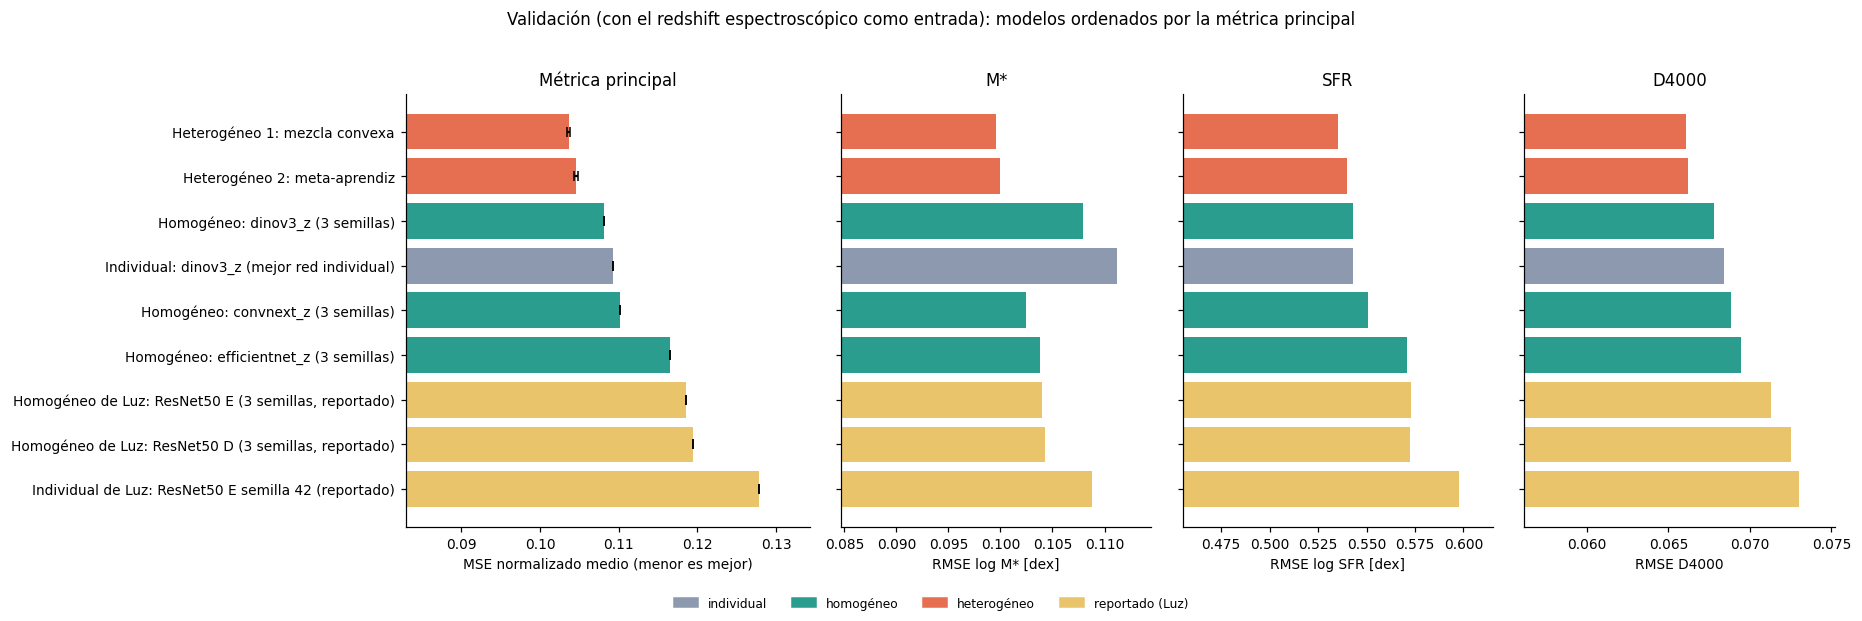

In [8]:
fig, ejes = plt.subplots(1, 4, figsize=(17, 0.9 + 0.5 * len(TABLA_VALIDACION)), sharey=True, gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
y_pos = np.arange(len(TABLA_VALIDACION))[::-1]
paleta = {"individual": "#8d99ae", "homogéneo": "#2a9d8f", "heterogéneo": "#e76f51", "reportado (Luz)": "#e9c46a"}
colores = [paleta[t] for t in TABLA_VALIDACION.tipo]
ejes[0].barh(y_pos, TABLA_VALIDACION.criterio, color=colores, xerr=TABLA_VALIDACION["desviación entre repeticiones"].fillna(0), capsize=3)
ejes[0].set(yticks=y_pos, yticklabels=TABLA_VALIDACION.modelo, xlabel="MSE normalizado medio (menor es mejor)", title="Métrica principal")
ejes[0].set_xlim(TABLA_VALIDACION.criterio.min() * 0.8, TABLA_VALIDACION.criterio.max() * 1.05)
for eje, t in zip(ejes[1:], OBJETIVOS):
    eje.barh(y_pos, TABLA_VALIDACION[f"RMSE {CORTO[t]}"], color=colores); eje.set(xlabel=f"RMSE {NOMBRES[t]}", title=CORTO[t])
    eje.set_xlim(TABLA_VALIDACION[f"RMSE {CORTO[t]}"].min() * 0.85, TABLA_VALIDACION[f"RMSE {CORTO[t]}"].max() * 1.03)
usados = [t for t in paleta if t in set(TABLA_VALIDACION.tipo)]
fig.legend([plt.Rectangle((0, 0), 1, 1, color=paleta[t]) for t in usados], usados, loc="lower center", ncol=len(usados), frameon=False, fontsize=8)
plt.suptitle(f"Validación ({PISTAS[PISTA]['descripcion']}): modelos ordenados por la métrica principal", y=1.02)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

Los dos heterogéneos encabezan la comparación, con 0.1037 la mezcla convexa y 0.1046 el meta-aprendiz, seguidos del homogéneo de DINOv3 (0.1081). La mezcla convexa tiene el menor RMSE en las tres propiedades a la vez: 0.0996 dex en la masa, 0.535 dex en la SFR y 0.066 en el D4000. Frente al mejor ensamble de Luz (ResNet50 E, 0.1186), su criterio es 13 % menor, aunque una parte se debe al TTA, con la mayor parte de la ventaja en la SFR (0.535 contra 0.573 dex) y el D4000 (0.066 contra 0.071), porque en la masa todos los modelos con redshift quedan entre 0.100 y 0.111 dex. El costo crece con la precisión. La mezcla convexa ejecuta nueve redes por galaxia y necesita 10.6 ms por galaxia sin TTA (2.95 horas de GPU por millón de galaxias), contra 2.7 ms de una sola red de DINOv3 y 0.44 ms de una ResNet50; casi todo ese costo corresponde a las tres redes de DINOv3 (8.1 ms).

## 7. Selección del modelo final

La métrica principal no es el único criterio. El objetivo del proyecto es extender las propiedades espectroscópicas a galaxias que solo tienen imagen, y eso hace que importen el desempeño, la estabilidad, el costo de usar el modelo en catálogos grandes y los datos que necesita al predecir. Para que la decisión no premie una mejora que no se distingue del ruido a cambio de ejecutar nueve redes por galaxia en lugar de una, aplicamos la **regla de un error estándar** que usamos en la fase de ingeniería del Avance 3 (Hastie et al. 2009, §7.10): entre los modelos que no se distinguen del mejor en más de un error estándar, elegimos el más simple, que medimos por el número de redes que hay que ejecutar para cada galaxia.

Adaptamos la regla a que todos los modelos predicen las mismas galaxias. El error estándar que usamos es el de la **diferencia pareada** de la pérdida por galaxia entre cada modelo y el mejor. La versión sin parear mide la dispersión de la pérdida entre galaxias, que crece con las galaxias difíciles para todos los modelos (en la SFR, las galaxias apagadas); cuando los errores de los modelos están correlacionados, como esperamos aquí, esa dispersión es común a todos y puede declarar empatados a modelos que la comparación pareada distingue. Las pérdidas de los ensambles heterogéneos son las de sus predicciones fuera de pliegue, promediadas entre las repeticiones de la validación cruzada. Fijamos esta regla antes de tener las predicciones reales, decidimos antes de abrir el conjunto de prueba y registramos la elección con una huella de sus predicciones de validación: si el cuaderno se volviera a ejecutar con otro modelo elegido, el registro lo detectaría.

In [9]:
COMPLEJIDAD = dict(zip(COMPARACION.modelo, COMPARACION["redes por galaxia"]))
ELEGIDO, TABLA_REGLA, DETALLE_REGLA = ensambles.regla_un_error_estandar({n: PERDIDAS[n] for n in COMPARACION.modelo}, COMPLEJIDAD)
display(TABLA_REGLA.round(4))
print(f"Mejor criterio: {DETALLE_REGLA['mejor']}\nModelo elegido por la regla: {ELEGIDO}\n"
      f"(Como referencia, el error estándar sin parear del mejor sería {DETALLE_REGLA['error_estandar_sin_parear']:.4f}.)")

,criterio,diferencia con el mejor,error estándar de la diferencia,complejidad,dentro de 1 error estándar
Heterogéneo 1: mezcla convexa,0.1037,0.0000,0.0000,9,True
Heterogéneo 2: meta-aprendiz,0.1046,0.0009,0.0003,9,False
Homogéneo: dinov3_z (3 semillas),0.1081,0.0044,0.0015,3,False
Individual: dinov3_z (mejor red individual),0.1092,0.0056,0.0017,1,False
Homogéneo: convnext_z (3 semillas),0.1102,0.0065,0.0015,3,False
Homogéneo: efficientnet_z (3 semillas),0.1165,0.0128,0.0023,3,False


Mejor criterio: Heterogéneo 1: mezcla convexa
Modelo elegido por la regla: Heterogéneo 1: mezcla convexa
(Como referencia, el error estándar sin parear del mejor sería 0.0054.)


In [10]:
NEGOCIO = COMPARACION[["modelo", "criterio", "desviación entre repeticiones", "redes por galaxia", "horas de GPU por millón"]].copy()
NEGOCIO["entradas al predecir"] = "imagen + redshift espectroscópico" if PISTA == "con_redshift" else "solo imagen"
NEGOCIO["diferencia con el mejor"] = NEGOCIO.modelo.map(TABLA_REGLA["diferencia con el mejor"])
NEGOCIO["error estándar de la diferencia"] = NEGOCIO.modelo.map(TABLA_REGLA["error estándar de la diferencia"])
NEGOCIO["dentro de 1 error estándar"] = NEGOCIO.modelo.map(TABLA_REGLA["dentro de 1 error estándar"])
display(NEGOCIO.round(4).fillna({"desviación entre repeticiones": "no aplica"}).fillna("no reportado"))

,modelo,criterio,desviación entre repeticiones,redes por galaxia,horas de GPU por millón,entradas al predecir,diferencia con el mejor,error estándar de la diferencia,dentro de 1 error estándar
lugar,,,,,,,,,
1,Heterogéneo 1: mezcla convexa,0.1037,0.0002,9,2.9497,imagen + redshift espectroscópico,0.0000,0.0000,True
2,Heterogéneo 2: meta-aprendiz,0.1046,0.0003,9,2.9497,imagen + redshift espectroscópico,0.0009,0.0003,False
3,Homogéneo: dinov3_z (3 semillas),0.1081,no aplica,3,2.2437,imagen + redshift espectroscópico,0.0044,0.0015,False
4,Individual: dinov3_z (mejor red individual),0.1092,no aplica,1,0.7479,imagen + redshift espectroscópico,0.0056,0.0017,False
5,Homogéneo: convnext_z (3 semillas),0.1102,no aplica,3,0.3760,imagen + redshift espectroscópico,0.0065,0.0015,False
6,Homogéneo: efficientnet_z (3 semillas),0.1165,no aplica,3,0.3300,imagen + redshift espectroscópico,0.0128,0.0023,False


La regla elige la mezcla convexa: es la de menor criterio, y ningún otro modelo queda a menos de un error estándar de ella. El meta-aprendiz, que tiene la misma complejidad, está 0.0009 por encima con un error estándar de la diferencia de 0.0003, y el homogéneo de DINOv3, con tres redes en lugar de nueve, está 0.0044 por encima con un error estándar de 0.0015. Sin parear, el error estándar sería de 0.0054 y la regla habría elegido el homogéneo de DINOv3, aunque la comparación pareada lo distingue claramente de la mezcla convexa. El promedio simple de las tres familias, que no tiene hiperparámetros, no está en la tabla porque no es uno de los dos heterogéneos que construimos, pero en el cuaderno de ensambles heterogéneos empata con la mezcla convexa (0.1038 contra 0.1037) con el mismo costo, así que sería una alternativa equivalente.

Desde el punto de vista del uso, el modelo elegido necesita el redshift espectroscópico de cada galaxia. Por eso se aplica a galaxias con espectro, como las de MaNGA o las del catálogo espectroscópico de SDSS, y no a las que solo tienen imagen. Para un catálogo de un millón de galaxias, del orden del espectroscópico de SDSS, costaría unas 3 horas de GPU sin TTA o unas 24 con TTA.

## 8. Evaluación en el conjunto de prueba

Con el modelo ya elegido y registrado, abrimos el conjunto de prueba **una sola vez**. Los combinadores heterogéneos se ajustaron con toda la validación y se aplicaron sin cambios a las predicciones de prueba de los miembros. Además del modelo final, reportamos los demás modelos de la comparación solo como contexto: sus resultados no pueden cambiar la elección, que ya está registrada.

Como referencia externa incluimos a Katachi (Alfonzo et al. 2024). Sus cifras publicadas (RMSE de 0.22, 0.75 y 0.28 en su conjunto de prueba de SDSS) no se pueden comparar galaxia por galaxia con las nuestras, así que las mostramos como referencia; sus pesos publicados evaluados sobre nuestras galaxias de prueba y la cadena de ResNet50 que reentrenamos con imágenes de DESI en el Avance 3 (media de tres semillas) sí son comparables.

**Independencia de la prueba.** Ninguna decisión de este avance usó el conjunto de prueba. En el Avance 4 sí evaluamos en prueba, una sola vez, las versiones de solo imagen de DINOv3 y ConvNeXt; de ellas tomamos aquí la arquitectura y los hiperparámetros de las versiones con redshift, pero esos hiperparámetros se eligieron en validación antes de aquella evaluación. Las redes con redshift, los combinadores y la elección del modelo final no han visto la prueba.

In [11]:
RUTA_REGISTRO = CARPETA_ENTREGA / f"registro_eleccion_{PISTA}.json"
REGISTRO = ensambles.registrar_eleccion(RUTA_REGISTRO, {"pista": PISTA, "modelo": ELEGIDO, "commit": COMMIT,
                                                        "criterio_validacion": float(COMPARACION.set_index("modelo").loc[ELEGIDO, "criterio"])},
                                        PRED_VAL[ELEGIDO])
TIPO = dict(zip(COMPARACION.modelo, COMPARACION.tipo))
filas = [{**metricas_largas(n, Y_PRUEBA, PRED_PRUEBA[n], tipo=TIPO[n]), "elegido": n == ELEGIDO} for n in COMPARACION.modelo]
TABLA_PRUEBA = pd.DataFrame(filas).sort_values("criterio").reset_index(drop=True)
display(TABLA_PRUEBA[["modelo", "elegido", "criterio", "RMSE M*", "RMSE SFR", "RMSE D4000", "MAE M*", "MAE SFR", "MAE D4000", "R2 M*", "R2 SFR", "R2 D4000"]].round(4))

REFERENCIAS_KATACHI = pd.DataFrame({"RMSE M*": [0.22, 0.222, 0.223], "RMSE SFR": [0.75, 0.668, 0.653], "RMSE D4000": [0.28, 0.100, 0.073]},
                                   index=["Katachi, artículo (SDSS, otra muestra; no pareable)", "Katachi, pesos publicados en nuestras galaxias de prueba",
                                          "Katachi reentrenado con DESI (Avance 3, media de 3 semillas)"])
display(REFERENCIAS_KATACHI)

Elección registrada antes de abrir la prueba.


,modelo,elegido,criterio,RMSE M*,RMSE SFR,RMSE D4000,MAE M*,MAE SFR,MAE D4000,R2 M*,R2 SFR,R2 D4000
0,Heterogéneo 1: mezcla convexa,True,0.1102,0.0969,0.5575,0.0676,0.0728,0.3544,0.0482,0.9760,0.7892,0.9201
1,Homogéneo: convnext_z (3 semillas),False,0.1120,0.1011,0.5545,0.0702,0.0766,0.3580,0.0505,0.9738,0.7914,0.9139
2,Heterogéneo 2: meta-aprendiz,False,0.1124,0.0959,0.5644,0.0682,0.0718,0.3585,0.0489,0.9765,0.7839,0.9187
3,Homogéneo: dinov3_z (3 semillas),False,0.1193,0.1059,0.5799,0.0694,0.0785,0.3704,0.0496,0.9713,0.7719,0.9157
4,Individual: dinov3_z (mejor red individual),False,0.1217,0.1090,0.5835,0.0704,0.0805,0.3760,0.0502,0.9696,0.7690,0.9134
5,Homogéneo: efficientnet_z (3 semillas),False,0.1242,0.0989,0.5962,0.0710,0.0754,0.3801,0.0510,0.9749,0.7589,0.9119


,RMSE M*,RMSE SFR,RMSE D4000
"Katachi, artículo (SDSS, otra muestra; no pareable)",0.220,0.750,0.280
"Katachi, pesos publicados en nuestras galaxias de prueba",0.222,0.668,0.100
"Katachi reentrenado con DESI (Avance 3, media de 3 semillas)",0.223,0.653,0.073


En prueba, la mezcla convexa es también el mejor modelo, con un criterio de 0.1102 y un RMSE de 0.097 dex en la masa, 0.558 dex en la SFR y 0.068 en el D4000. El orden de los demás cambia: el homogéneo de ConvNeXt pasa al segundo lugar (0.1120) y tiene incluso el menor RMSE en la SFR (0.555 dex), mientras que el homogéneo de DINOv3 baja al cuarto (0.1193). Todos los modelos empeoran de validación a prueba, la mezcla convexa en 6 % y el homogéneo de DINOv3 en 10 %, así que la prueba resulta más difícil para todos.

Frente a Katachi en las mismas galaxias de prueba, el modelo final reduce el RMSE de la masa a menos de la mitad (0.097 contra 0.222 dex), el de la SFR en 16 % (0.558 contra 0.668) y el del D4000 en 32 % (0.068 contra 0.100). Parte de la ventaja en la masa se debe al redshift espectroscópico, que Katachi no recibe. Frente a la cadena de Katachi reentrenada con DESI en el Avance 3, la mejora en el D4000 es menor (0.068 contra 0.073).

Para saber si el modelo final es mejor que los demás con una diferencia que no se explique por el azar de la muestra, comparamos con un *bootstrap* pareado: remuestreamos las galaxias de prueba y calculamos en cada remuestreo la diferencia del criterio entre dos modelos. Si el intervalo del 95 % de esa diferencia excluye el cero, la diferencia es significativa. La gráfica muestra las diferencias de la tabla con sus intervalos, y la brecha entre validación y prueba de cada modelo, que indica si generaliza.

,Δ criterio (final − otro),límite inferior,límite superior,veredicto
comparado con,,,,
Homogéneo: efficientnet_z (3 semillas),-0.0140,-0.0198,-0.0087,el final es mejor
Individual: dinov3_z (mejor red individual),-0.0115,-0.0158,-0.0070,el final es mejor
Homogéneo: dinov3_z (3 semillas),-0.0091,-0.0129,-0.0052,el final es mejor
Heterogéneo 2: meta-aprendiz,-0.0022,-0.0046,0.0000,sin diferencia significativa
Homogéneo: convnext_z (3 semillas),-0.0018,-0.0057,0.0019,sin diferencia significativa


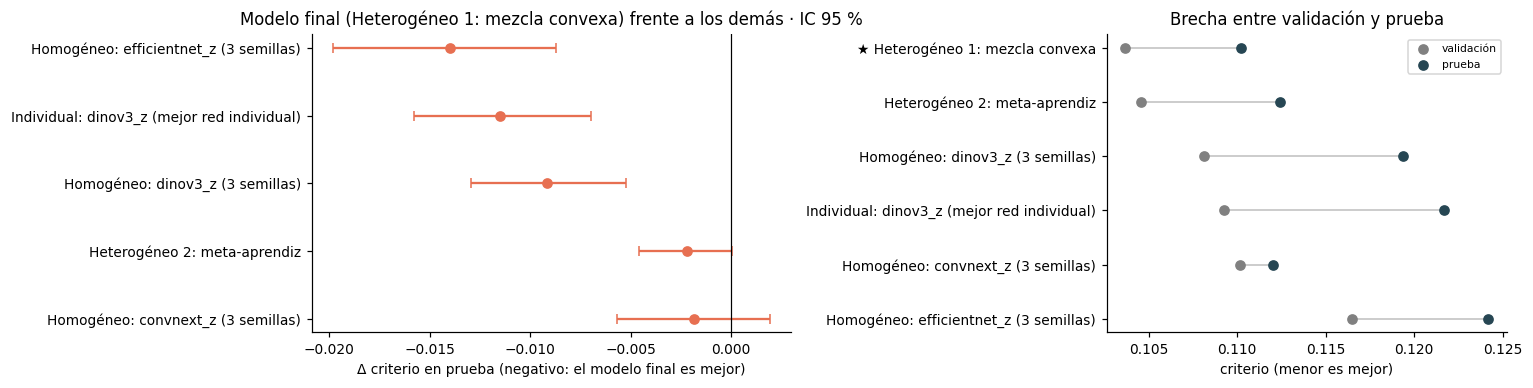

In [12]:
FINAL_PRUEBA = PRED_PRUEBA[ELEGIDO]
filas = []
for nombre in COMPARACION.modelo:
    if nombre == ELEGIDO:
        continue
    d, lo, hi = ensambles.diferencia_pareada_criterio(Y_PRUEBA, FINAL_PRUEBA, PRED_PRUEBA[nombre], ESCALA, N_REMUESTREOS)
    filas.append({"comparado con": nombre, "Δ criterio (final − otro)": d, "límite inferior": lo, "límite superior": hi,
                  "veredicto": "el final es mejor" if hi < 0 else ("el final es peor" if lo > 0 else "sin diferencia significativa")})
PAREADA = pd.DataFrame(filas).set_index("comparado con").sort_values("Δ criterio (final − otro)")
display(PAREADA.round(4))

criterio_val = COMPARACION.set_index("modelo").criterio
criterio_prueba = TABLA_PRUEBA.set_index("modelo").criterio
fig, ejes = plt.subplots(1, 2, figsize=(14, 0.9 + 0.45 * len(COMPARACION)), gridspec_kw={"width_ratios": [1.2, 1]})
y_pos = np.arange(len(PAREADA))[::-1]
ejes[0].errorbar(PAREADA["Δ criterio (final − otro)"], y_pos, xerr=[PAREADA["Δ criterio (final − otro)"] - PAREADA["límite inferior"],
                 PAREADA["límite superior"] - PAREADA["Δ criterio (final − otro)"]], fmt="o", color="#e76f51", capsize=3)
ejes[0].axvline(0, color="k", lw=0.8)
ejes[0].set(yticks=y_pos, yticklabels=PAREADA.index, xlabel="Δ criterio en prueba (negativo: el modelo final es mejor)",
            title=f"Modelo final ({ELEGIDO}) frente a los demás · IC 95 %")
orden = list(criterio_val.sort_values().index)
y2 = np.arange(len(orden))[::-1]
ejes[1].scatter(criterio_val[orden], y2, color="0.5", label="validación", zorder=3)
ejes[1].scatter(criterio_prueba[orden], y2, color="#264653", label="prueba", zorder=3)
for yy, m in zip(y2, orden):
    ejes[1].plot([criterio_val[m], criterio_prueba[m]], [yy, yy], color="0.75", lw=1)
ejes[1].set(yticks=y2, yticklabels=[("★ " if m == ELEGIDO else "") + m for m in orden], xlabel="criterio (menor es mejor)", title="Brecha entre validación y prueba")
ejes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

El modelo final es significativamente mejor en prueba que la mejor red individual (0.0115 menos, IC del 95 % de −0.0158 a −0.0070), que el homogéneo de DINOv3 y que el de EfficientNet. Frente al meta-aprendiz (−0.0022, de −0.0046 a 0.0000) y al homogéneo de ConvNeXt (−0.0018, de −0.0057 a +0.0019), la diferencia no es significativa.

Este último resultado tiene una lectura de negocio. El homogéneo de ConvNeXt ejecuta tres redes con 1.35 ms por galaxia, casi ocho veces menos que la mezcla convexa, y en prueba no se distingue de ella. En validación sí se distinguía (0.0065 por encima, con un error estándar de 0.0015), y por eso la regla, que fijamos antes de abrir la prueba, eligió la mezcla convexa. No cambiamos la elección después de ver la prueba, pero si el costo de cómputo fuera la restricción principal, el homogéneo de ConvNeXt sería una alternativa razonable.

La gráfica de la derecha muestra que la mezcla convexa tiene la segunda brecha más pequeña entre validación y prueba (pasa de 0.1037 a 0.1102), después del homogéneo de ConvNeXt (de 0.1102 a 0.1120), y que las mayores son las de DINOv3 (0.011 en el homogéneo y 0.013 en la red individual).

## 9. Gráficos del modelo final

Como nuestro problema es de regresión, las curvas ROC y las matrices de confusión no aplican; usamos los gráficos propios de la regresión. Para el modelo final y sobre las galaxias de prueba, que ningún paso del proceso había visto, mostramos la concordancia entre predicción y etiqueta, la distribución de los residuos, cómo cambia el error con el valor de la propiedad y con el redshift, y si el desacuerdo entre familias sirve como señal de incertidumbre. Cerramos con lo que aporta cada familia al modelo final, medido en validación por el cuaderno de ensambles heterogéneos. En los gráficos de residuos comparamos con la mejor red individual.

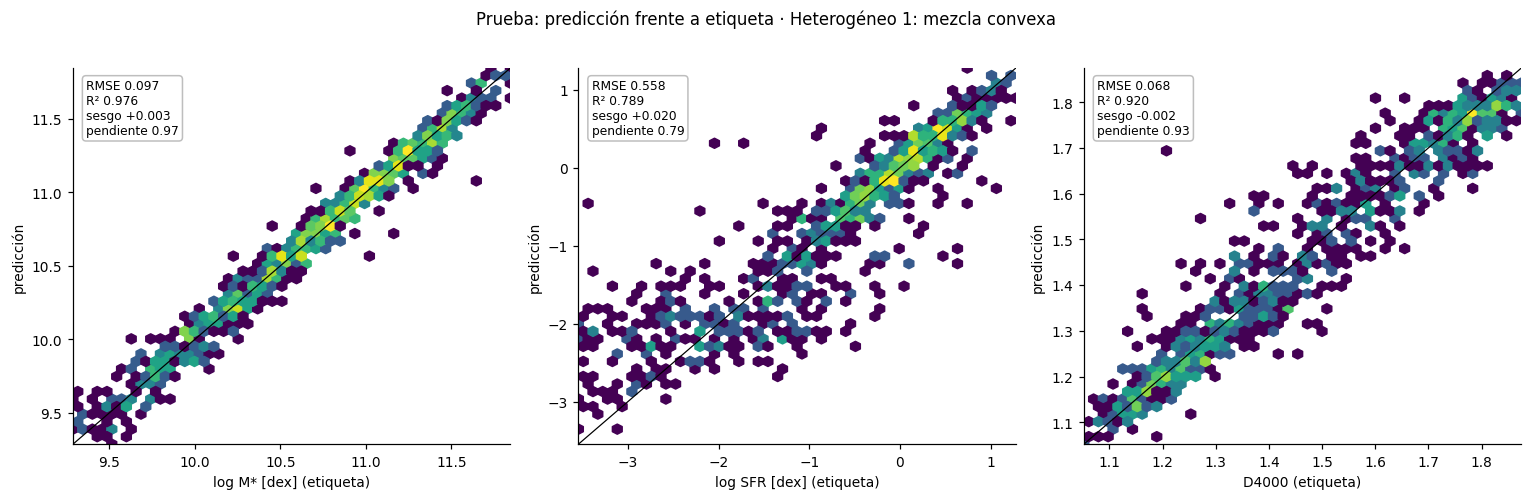

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.4))
for k, (eje, t) in enumerate(zip(ejes, OBJETIVOS)):
    y, p = Y_PRUEBA[:, k], FINAL_PRUEBA[:, k]
    lim = np.percentile(np.r_[y, p], [0.5, 99.5])
    eje.hexbin(y, p, gridsize=45, cmap="viridis", mincnt=1, bins="log", extent=(*lim, *lim)); eje.plot(lim, lim, "k-", lw=0.8)
    m = evaluacion.metricas(y, p)
    eje.text(0.03, 0.97, f"RMSE {m['RMSE']:.3f}\nR² {m['R2']:.3f}\nsesgo {m['sesgo']:+.3f}\npendiente {ensambles.pendiente_de_calibracion(y, p):.2f}",
             transform=eje.transAxes, va="top", fontsize=8, bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.7"))
    eje.set(xlim=lim, ylim=lim, xlabel=f"{NOMBRES[t]} (etiqueta)", ylabel="predicción")
plt.suptitle(f"Prueba: predicción frente a etiqueta · {ELEGIDO}", y=1.02); plt.tight_layout(); plt.show()

En prueba, la mezcla convexa explica el 97.6 % de la varianza de la masa, el 78.9 % de la SFR y el 92.0 % del D4000, con sesgos de +0.003 dex, +0.020 dex y −0.002. La masa y el D4000 siguen la línea 1:1 en casi todo su rango (pendientes de 0.97 y 0.93). La SFR tiene la mayor dispersión y una pendiente de 0.79: las galaxias con log SFR por debajo de −2.5 se predicen alrededor de −2, y hay galaxias dispersas a más de 1 dex de la línea en ambos sentidos. Es la misma compresión que tenían los miembros, porque una mezcla convexa no puede extender las predicciones más allá del intervalo que abarcan sus miembros.

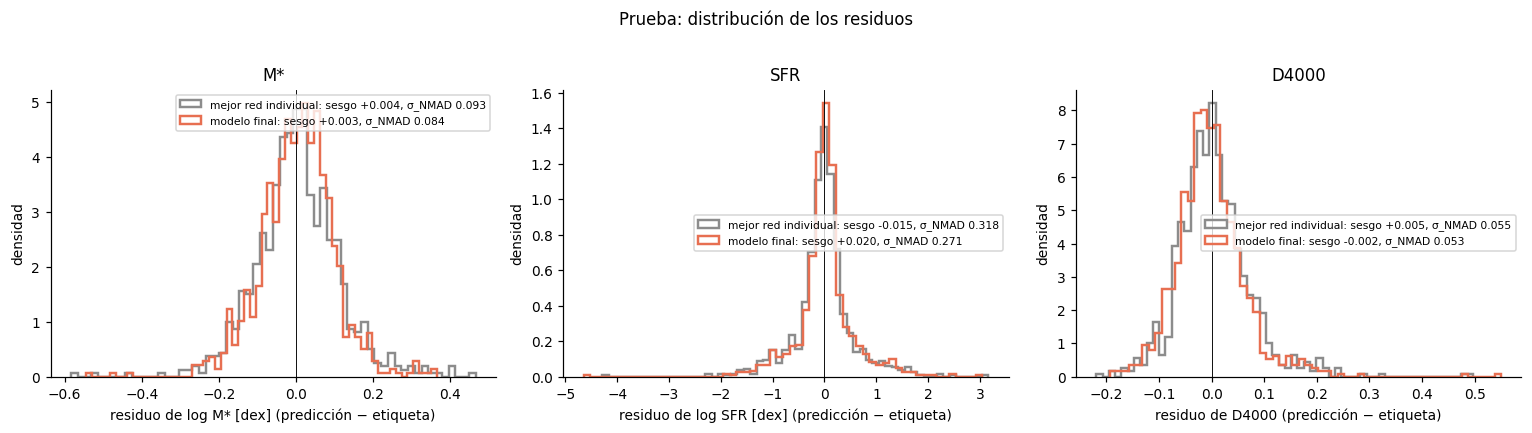

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for k, (eje, t) in enumerate(zip(ejes, OBJETIVOS)):
    for nombre, color, etiqueta in ((NOMBRE_INDIVIDUAL, "0.55", "mejor red individual"), (ELEGIDO, "#e76f51", "modelo final")):
        r = PRED_PRUEBA[nombre][:, k] - Y_PRUEBA[:, k]
        nmad = evaluacion.metricas(Y_PRUEBA[:, k], PRED_PRUEBA[nombre][:, k])["sigma_NMAD"]
        eje.hist(r, bins=60, density=True, histtype="step", lw=1.6, color=color, label=f"{etiqueta}: sesgo {r.mean():+.3f}, σ_NMAD {nmad:.3f}")
    eje.axvline(0, color="k", lw=0.6); eje.set(xlabel=f"residuo de {NOMBRES[t]} (predicción − etiqueta)", ylabel="densidad", title=CORTO[t]); eje.legend(fontsize=7)
plt.suptitle("Prueba: distribución de los residuos", y=1.02); plt.tight_layout(); plt.show()

Frente a la mejor red individual, la mezcla convexa estrecha el centro de la distribución de los residuos en las tres propiedades: la σ_NMAD baja de 0.093 a 0.084 dex en la masa, de 0.318 a 0.271 dex en la SFR y de 0.055 a 0.053 en el D4000. Los sesgos son pequeños en los dos modelos (menos de 0.02 dex en valor absoluto). Las colas casi no cambian: en la SFR, los residuos de más de 1 dex siguen presentes con los dos modelos, lo que indica que esos errores son comunes a todas las arquitecturas y no se compensan al combinarlas.

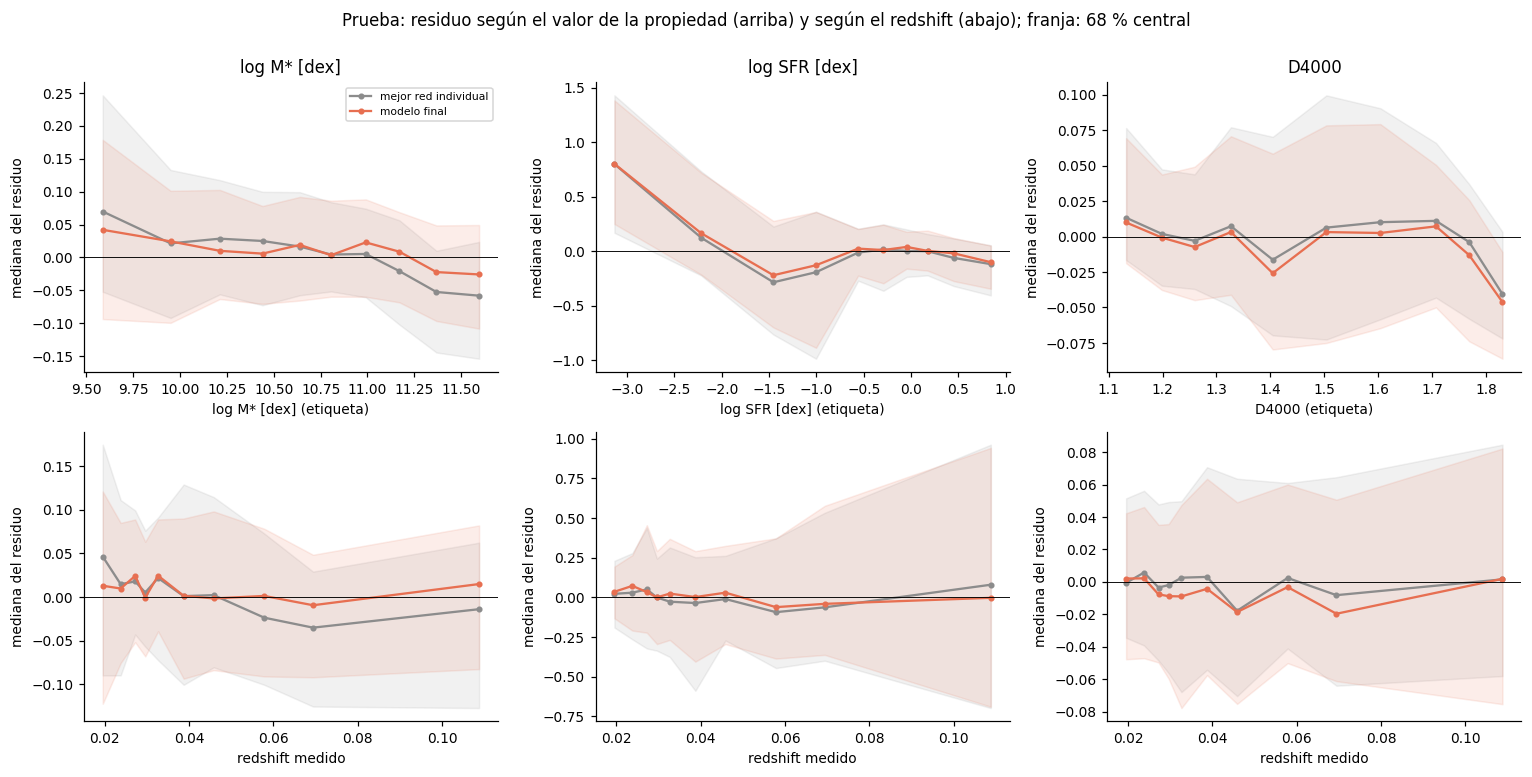

In [15]:
def mediana_por_intervalos(x, residuo, n=10):
    n = int(max(2, min(n, len(x) // 12)))
    bordes = np.quantile(x, np.linspace(0, 1, n + 1)); centro, med, p16, p84 = [], [], [], []
    for a, b in zip(bordes[:-1], bordes[1:]):
        s = (x >= a) & (x <= b)
        if s.sum() >= 4:
            centro.append(np.median(x[s])); med.append(np.median(residuo[s])); p16.append(np.percentile(residuo[s], 16)); p84.append(np.percentile(residuo[s], 84))
    return map(np.array, (centro, med, p16, p84))

fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for k, t in enumerate(OBJETIVOS):
    for fila, (x, nombre_x) in enumerate(((Y_PRUEBA[:, k], f"{NOMBRES[t]} (etiqueta)"), (Z_PRUEBA, "redshift medido"))):
        for nombre, color, etiqueta in ((NOMBRE_INDIVIDUAL, "0.55", "mejor red individual"), (ELEGIDO, "#e76f51", "modelo final")):
            cx, med, p16, p84 = mediana_por_intervalos(x, PRED_PRUEBA[nombre][:, k] - Y_PRUEBA[:, k])
            ejes[fila, k].plot(cx, med, "o-", ms=3, color=color, label=etiqueta); ejes[fila, k].fill_between(cx, p16, p84, color=color, alpha=0.12)
        ejes[fila, k].axhline(0, color="k", lw=0.6); ejes[fila, k].set(xlabel=nombre_x, ylabel="mediana del residuo")
    ejes[0, k].set_title(NOMBRES[t])
ejes[0, 0].legend(fontsize=7)
plt.suptitle("Prueba: residuo según el valor de la propiedad (arriba) y según el redshift (abajo); franja: 68 % central", y=1.0)
plt.tight_layout(); plt.show()

En la fila de arriba, la mezcla convexa reduce el sesgo de la masa en los extremos: en las galaxias menos masivas pasa de +0.07 a +0.04 dex, y en las más masivas, de −0.06 a −0.03 dex. En la SFR, los dos modelos sobrestiman en unos 0.8 dex a las galaxias más apagadas (log SFR ≈ −3) y subestiman en unos 0.2 dex alrededor de log SFR ≈ −1.5. El ensamble no corrige este sesgo, que es la principal limitación del modelo. En el D4000, los dos subestiman en unos 0.045 a las poblaciones más viejas (D4000 > 1.8).

En la fila de abajo, el residuo de la masa de la mezcla convexa se mantiene entre −0.01 y +0.02 dex en todo el intervalo de redshift, mientras que el de la red individual llega a −0.035 dex hacia z ≈ 0.07. Ni la SFR ni el D4000 muestran tendencias con la distancia.

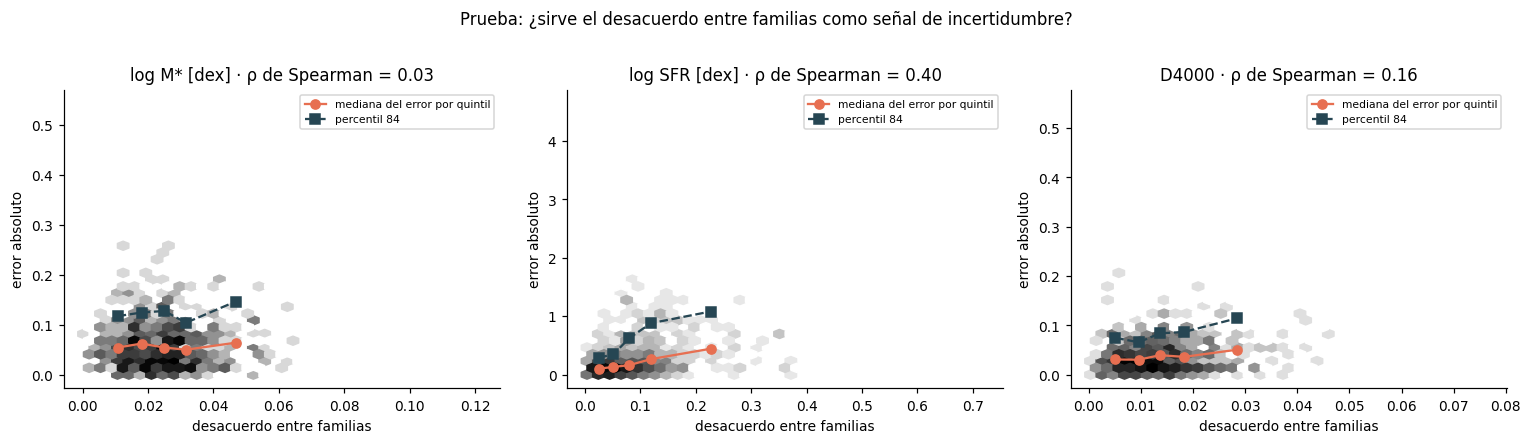

In [16]:
# Desacuerdo entre familias como señal de incertidumbre: ¿los casos en que los miembros discrepan son los que más fallan?
DESACUERDO = ensambles.desacuerdo_ponderado(P_PRUEBA, PESOS_H1 if ELEGIDO == NOMBRE_H1 else None)
ERROR_ABSOLUTO = np.abs(FINAL_PRUEBA - Y_PRUEBA)
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.9))
for k, (eje, t) in enumerate(zip(ejes, OBJETIVOS)):
    cuantiles = np.quantile(DESACUERDO[:, k], np.linspace(0, 1, 6))
    grupo = np.clip(np.searchsorted(cuantiles, DESACUERDO[:, k], side="right") - 1, 0, 4)
    centros = [np.median(DESACUERDO[grupo == g, k]) for g in range(5)]
    medianas = [np.median(ERROR_ABSOLUTO[grupo == g, k]) for g in range(5)]
    p84 = [np.percentile(ERROR_ABSOLUTO[grupo == g, k], 84) for g in range(5)]
    rho = spearmanr(DESACUERDO[:, k], ERROR_ABSOLUTO[:, k]).statistic
    eje.hexbin(DESACUERDO[:, k], ERROR_ABSOLUTO[:, k], gridsize=35, cmap="Greys", mincnt=1, bins="log")
    eje.plot(centros, medianas, "o-", color="#e76f51", label="mediana del error por quintil"); eje.plot(centros, p84, "s--", color="#264653", label="percentil 84")
    eje.set(xlabel="desacuerdo entre familias", ylabel="error absoluto", title=f"{NOMBRES[t]} · ρ de Spearman = {rho:.2f}"); eje.legend(fontsize=7)
plt.suptitle("Prueba: ¿sirve el desacuerdo entre familias como señal de incertidumbre?", y=1.02); plt.tight_layout(); plt.show()

El desacuerdo entre las familias sirve como señal de incertidumbre solo en la SFR. Ahí su correlación de Spearman con el error es de 0.40, y la mediana del error absoluto sube de unos 0.1 dex en el quintil de menor desacuerdo a unos 0.45 dex en el de mayor, mientras que el percentil 84 pasa de 0.3 a 1.1 dex. En el D4000 la relación es débil (ρ = 0.16) y en la masa no existe (ρ = 0.03): las tres familias reciben el mismo redshift y sus errores de masa están correlacionados entre 0.86 y 0.88, así que también coinciden cuando se equivocan. En la práctica, el desacuerdo permite marcar las estimaciones de SFR poco confiables, pero no las de masa.

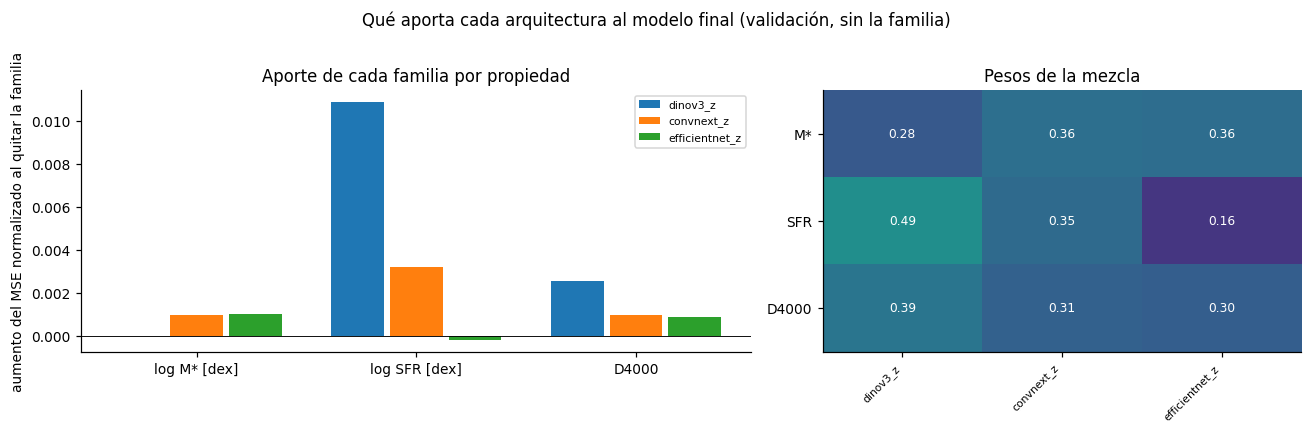

In [17]:
# Aporte de cada familia al modelo final, calculado en validación por el cuaderno de ensambles heterogéneos.
if TIPO[ELEGIDO] == "heterogéneo":
    a = APORTE[APORTE.ensamble == ELEGIDO].set_index("familia").reindex(FAMILIAS_HETEROGENEO)
    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
    ancho = 0.8 / len(FAMILIAS_HETEROGENEO)
    for i, f in enumerate(FAMILIAS_HETEROGENEO):
        ejes[0].bar(np.arange(3) + i * ancho, [a.loc[f, f"aumento {CORTO[t]}"] for t in OBJETIVOS], ancho * 0.9, label=f)
    ejes[0].axhline(0, color="k", lw=0.6)
    ejes[0].set(xticks=np.arange(3) + ancho * (len(FAMILIAS_HETEROGENEO) - 1) / 2, xticklabels=[NOMBRES[t] for t in OBJETIVOS],
                ylabel="aumento del MSE normalizado al quitar la familia", title="Aporte de cada familia por propiedad"); ejes[0].legend(fontsize=7)
    if ELEGIDO == NOMBRE_H1:
        ejes[1].imshow(PESOS_H1.T, cmap="viridis", vmin=0, vmax=1, aspect="auto")
        ejes[1].set(xticks=range(len(FAMILIAS_HETEROGENEO)), yticks=range(3), yticklabels=[CORTO[t] for t in OBJETIVOS], title="Pesos de la mezcla")
        ejes[1].set_xticklabels(FAMILIAS_HETEROGENEO, rotation=45, ha="right", fontsize=7)
        for i in range(len(FAMILIAS_HETEROGENEO)):
            for j in range(3):
                ejes[1].text(i, j, f"{PESOS_H1[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w" if PESOS_H1[i, j] < 0.5 else "k")
    else:
        ejes[1].barh(range(len(FAMILIAS_HETEROGENEO)), a["aumento del criterio"], color="#e76f51")
        ejes[1].set(yticks=range(len(FAMILIAS_HETEROGENEO)), yticklabels=FAMILIAS_HETEROGENEO, xlabel="aumento del criterio global", title="Aporte global")
    plt.suptitle("Qué aporta cada arquitectura al modelo final (validación, sin la familia)", y=1.02); plt.tight_layout(); plt.show()
else:
    print("El modelo final no es un ensamble heterogéneo: no hay aportes por familia que mostrar.")

Al quitar DINOv3, el MSE normalizado de la SFR sube 0.011 y el del D4000 0.0025, mientras que el de la masa no cambia. DINOv3 aporta la SFR y el D4000; ConvNeXt y EfficientNet aportan la masa, donde son mejores y reciben los pesos más altos (0.36 cada una). Los pesos de la derecha reflejan esa división, con 0.49 para DINOv3 en la SFR. EfficientNet aporta poco en conjunto (0.0006 en el criterio), y en la SFR su ausencia incluso mejora ligeramente el resultado.

## 10. Conclusiones

Comparamos siete ensambles: cinco homogéneos (los dos de ResNet50 de Luz y los de DINOv3, ConvNeXt y EfficientNet-B3 con redshift) y dos heterogéneos (una mezcla convexa y un meta-aprendiz). El modelo final, elegido en validación con la regla de un error estándar pareada, es la **mezcla convexa** de DINOv3, ConvNeXt y EfficientNet-B3 con el redshift espectroscópico como entrada, con nueve redes por galaxia. En validación logra un criterio de 0.1037, y en prueba, evaluada una sola vez, 0.1102, con RMSE de 0.097 dex en la masa, 0.558 dex en la SFR y 0.068 en el D4000 y coeficientes R² de 0.976, 0.789 y 0.920.

El ensamble mejora de forma significativa a la mejor red individual también en prueba (9 % menos de error, de 0.1217 a 0.1102), y en validación queda 13 % por debajo del mejor ensamble de Luz, aunque parte de esa diferencia se debe al TTA. La ganancia viene de combinar arquitecturas que aciertan en propiedades distintas: DINOv3 en la SFR y el D4000, y ConvNeXt y EfficientNet en la masa. Aprender los pesos casi no mejora al promedio simple, y el meta-aprendiz no supera a la mezcla convexa, porque los errores de las tres familias están muy correlacionados (de 0.86 a 0.93).

El modelo final necesita el redshift espectroscópico, así que sirve para galaxias con espectro y no para las que solo tienen imagen. Para ese caso, el mejor modelo del equipo sigue siendo el DINOv3 de solo imagen del Avance 4, y la pista `solo_imagen` de estos cuadernos permite construir sus ensambles cambiando una sola variable. Usar el modelo final cuesta unas 3 horas de GPU por millón de galaxias sin TTA. Si el costo fuera la restricción principal, el homogéneo de ConvNeXt, que no se distingue del modelo final en prueba y es casi ocho veces más barato, sería la alternativa. EfficientNet-B3 casi no aporta, y un ensamble de DINOv3 y ConvNeXt conservaría prácticamente toda la ganancia.

La principal limitación es la compresión de la SFR. Los modelos sobrestiman en unos 0.8 dex a las galaxias más apagadas, y ningún ensamble lo corrige, porque todos los miembros comparten ese error. Otras dos limitaciones vienen del protocolo. La validación sirvió para elegir la época de cada red y para ajustar los combinadores, lo que mitigamos con la validación cruzada anidada y con una sola evaluación en prueba. Los ensambles de Luz solo pudieron compararse con sus métricas de validación, porque no contamos con sus predicciones galaxia por galaxia. Como trabajo futuro, la compresión de la SFR podría atacarse con las ideas de Zhong et al. (2024): predecir la sSFR en lugar de la SFR y entrenar con una pérdida absoluta.

## 11. Referencias

Alfonzo, J. P., Iyer, K. G., Akiyama, M., et al. (2024). Decoding the imprints of past star formation on present-day morphology in galaxies with interpretable CNNs. *The Astrophysical Journal*, 967, 152.

Breiman, L. (1996). Stacked regressions. *Machine Learning*, 24(1), 49–64.

Cawley, G. C. y Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research*, 11, 2079–2107.

Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer. Sección 7.10.

Krogh, A. y Vedelsby, J. (1995). Neural network ensembles, cross validation, and active learning. *Advances in Neural Information Processing Systems 7*, 231–238.

Singh, A. (2023, 14 de julio). Comprehensive guide to ensemble learning (with Python codes). *Analytics Vidhya*. https://www.analyticsvidhya.com/blog/2018/06/comprehensive-guide-for-ensemble-models/

Studer, S., Bui, T. B., Drescher, C., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction*, 3, 392–413.

VanderPlas, J. (2022). *Python Data Science Handbook* (2.ª ed.). O'Reilly Media. Capítulo 39, sección *Thinking about model validation*.

Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.

Zhong, J., Deng, Z., Li, X., Wang, L., Yang, H., Li, H. y Zhao, X. (2024). Estimation of stellar mass and star formation rate based on galaxy images. *Monthly Notices of the Royal Astronomical Society*, 531(1), 2011–2027.

# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). Claude [Modelo de lenguaje grande]. https://claude.ai/ | Escribir el código de los cuadernos de modelos base, de ensambles heterogéneos y de comparación final, con sus pruebas unitarias, y redactar los análisis a partir de los resultados | Este cuaderno, el de ensambles heterogéneos y el de entrenamiento de los modelos base | Ejecutamos los entrenamientos y los ensambles, comparamos cada cifra con las salidas de los cuadernos, corregimos el código y los textos, y validamos cada interpretación |
| OpenAI. (2026). ChatGPT (GPT-6) [Modelo de lenguaje grande]. https://chatgpt.com/ | Estructurar el código y revisar el procedimiento de comparación en los modelos 1, 2, 5 y 6 y en los ensambles homogéneos | Cuadernos de los modelos 1, 2, 5 y 6 y de los ensambles homogéneos, de los que este cuaderno toma las métricas de referencia de ResNet50 | Revisamos las salidas antes de interpretarlas y adaptamos el código a las variables astronómicas, con la orientación de los asesores |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Luz Copelia Minutti Pérez | Desarrolló y ejecutó los modelos 1 (ResNet50 multitarea), 2 (SVR), 5 (Ridge) y 6 (KNN), el protocolo común de comparación y los ensambles homogéneos de ResNet50 (variantes D y E), con la búsqueda de sus pesos y su análisis de importancia de las entradas. |
| Erick Alberto Bustos Cruz | Desarrolló y ejecutó los modelos 3 (ConvNeXt-Tiny) y 4 (DINOv3 con LoRA), entrenó los modelos base con redshift y EfficientNet-B3, construyó los ensambles heterogéneos y redactó la comparación, la selección y la evaluación del modelo final. |
| José Florencio Maguey Peralta | _Pendiente: el integrante debe completar su contribución._ |

### Decisiones principales

<small><b>Decisión 1:</b> Usar la validación como conjunto de reserva de los ensambles heterogéneos, con validación cruzada anidada</small>
- <small>Justificación: reentrenar cada red varias veces sobre pliegues del entrenamiento costaba horas de GPU por red, y la validación cruzada anidada permite medir el desempeño de los combinadores sin que las galaxias evaluadas hayan intervenido en su ajuste.</small>
- <small>Alternativa descartada y motivo: stacking con predicciones por pliegues sobre todo el entrenamiento, porque exigía entrenar de nuevo cada red varias veces (unas 2 horas con DINOv3 y unas 3 con ResNet50).</small>

<small><b>Decisión 2:</b> Construir los ensambles en dos pistas, con y sin el redshift espectroscópico, controladas por una sola variable</small>
- <small>Justificación: el redshift espectroscópico mejora mucho la masa, pero no existe para la mayoría de las galaxias que solo tienen imagen, y el uso final del modelo determina cuál pista conviene.</small>
- <small>Alternativa descartada y motivo: elegir una sola pista desde el inicio, porque habría ocultado cuánto se pierde al no conocer la distancia.</small>

<small><b>Decisión 3:</b> Elegir el modelo final con la regla de un error estándar pareada, y que el meta-aprendiz corrija el promedio uniforme</small>
- <small>Justificación: evita pagar el costo de ejecutar muchas redes por una mejora que no se distingue del ruido, y mantiene al meta-aprendiz cerca de un promedio razonable aunque haya solo 1,261 galaxias de reserva.</small>
- <small>Alternativa descartada y motivo: elegir el modelo con el menor criterio sin más, y un meta-aprendiz libre sobre las predicciones, porque puede sobreajustar con tan pocas galaxias.</small>